# Meme Kanseri Teşhisi: Logistic Regression ve Random Forest Karşılaştırması
**Proje türü:** Makine öğrenmesi — ikili sınıflandırma
**Veri:** Breast Cancer Wisconsin (Diagnostic) — UCI ML Repository, `sklearn.datasets.load_breast_cancer` ile yüklenir (internet gerekmez).
**Amaç:** Hücre çekirdeği ölçümlerinden bir kitlenin *malign (kötü huylu)* mu *benign (iyi huylu)* mu olduğunu tahmin etmek. Bu bir eğitim projesidir, klinik karar aracı değildir.

In [1]:
import numpy as np, pandas as pd, json
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score
sns.set_theme(style="whitegrid")
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()
# sklearn'de 0 = malign, 1 = benign. Okunabilirlik için hedefi çevirip malign'i "pozitif sınıf" (1) yapıyoruz.
df["malign"] = 1 - df["target"]; df = df.drop(columns="target")
print(df.shape); print("Eksik değer:", df.isnull().sum().sum())
print(df.malign.value_counts().rename({0: "benign", 1: "malign"}))

(569, 31)
Eksik değer: 0
malign
benign    357
malign    212
Name: count, dtype: int64


## 3. Veri Analizi
30 sayısal özellik vardır (10 ölçümün ortalama, standart hata ve "en kötü" değeri: yarıçap, doku, çevre, alan, pürüzsüzlük, ...). Eksik değer yoktur; kategorik değişken yoktur. Sınıflar hafif dengesizdir (%37 malign).

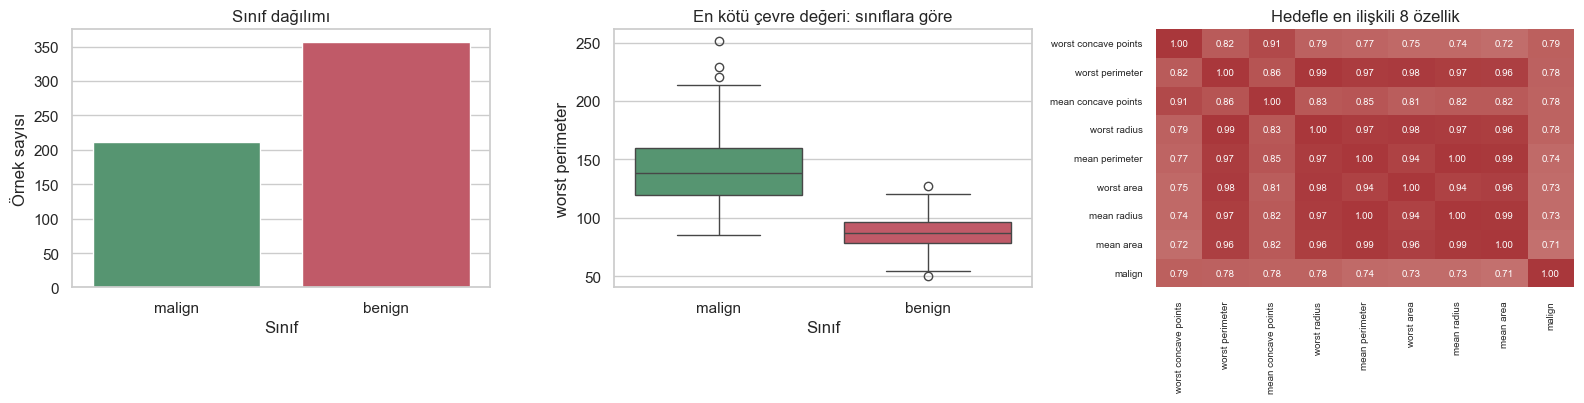

malign                  1.000
worst concave points    0.794
worst perimeter         0.783
mean concave points     0.777
worst radius            0.776
mean perimeter          0.743
Name: malign, dtype: float64


In [2]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
sns.countplot(x=df.malign.map({0: "benign", 1: "malign"}), ax=ax[0], hue=df.malign.map({0: "benign", 1: "malign"}), palette=["#4c9f70", "#d1495b"], legend=False)
ax[0].set_title("Sınıf dağılımı"); ax[0].set_xlabel("Sınıf"); ax[0].set_ylabel("Örnek sayısı")
sns.boxplot(data=df, x=df.malign.map({0: "benign", 1: "malign"}), y="worst perimeter", ax=ax[1], hue=df.malign.map({0: "benign", 1: "malign"}), palette=["#4c9f70", "#d1495b"], legend=False)
ax[1].set_title("En kötü çevre değeri: sınıflara göre"); ax[1].set_xlabel("Sınıf")
top = df.corr()["malign"].abs().sort_values(ascending=False).index[1:9]
sns.heatmap(df[list(top) + ["malign"]].corr(), annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax[2], annot_kws={"size": 7}, cbar=False)
ax[2].set_title("Hedefle en ilişkili 8 özellik"); ax[2].tick_params(labelsize=7)
plt.tight_layout(); plt.savefig("fig_eda.png", dpi=150); plt.show()
print(df.corr()["malign"].abs().sort_values(ascending=False).head(6).round(3))

Gözlemler: (1) Malign kitlelerde çevre, alan ve yarıçap gibi boyut ölçümleri belirgin biçimde daha büyük. (2) En güçlü ilişkili özellikler birbirleriyle de çok yüksek korelasyonlu (yarıçap–çevre–alan); bu **çoklu doğrusallık** Logistic Regression katsayılarının yorumunu zorlaştırır. (3) Sınıf dengesizliği hafif olduğu için accuracy yanında recall ve F1'e de bakılmalıdır.

## 4. Ön İşleme
- Eksik/aykırı değer: eksik yok; aykırı değerler tıbbi olarak anlamlı olabileceği için silinmedi.
- Veri bölme: **%80 eğitim / %20 test**, `stratify` ile sınıf oranı korunur.
- Ölçekleme: `StandardScaler`. Logistic Regression ölçeğe duyarlıdır; ağaç tabanlı model değildir ama aynı boru hattı kolaylık sağlar. Veri sızıntısını önlemek için ölçekleyici yalnızca eğitim verisine fit edilir (Pipeline içinde).

In [3]:
X = df.drop(columns="malign"); y = df["malign"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Eğitim:", X_train.shape, "Test:", X_test.shape, "| eğitimde malign oranı:", round(y_train.mean(), 3), "testte:", round(y_test.mean(), 3))

Eğitim: (455, 30) Test: (114, 30) | eğitimde malign oranı: 0.374 testte: 0.368


## 5–6. Model ve Eğitim
- **Model 1 — Logistic Regression** (temel model): hızlı, yorumlanabilir, doğrusal sınır. `C=1.0`, `max_iter=1000`.
- **Model 2 — Random Forest:** doğrusal olmayan ilişkileri ve özellik etkileşimlerini yakalayabilir. `n_estimators` ve `max_depth` **5 katlı çapraz doğrulama + GridSearchCV** ile seçilir (ölçüt: F1).
- Test seti hiperparametre seçiminde **kullanılmaz**; yalnızca son değerlendirmede bir kez kullanılır.

In [4]:
cv = StratifiedKFold(5, shuffle=True, random_state=42)
lr = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000, random_state=42))
rf_grid = GridSearchCV(
    make_pipeline(StandardScaler(), RandomForestClassifier(random_state=42)),
    {"randomforestclassifier__n_estimators": [100, 300], "randomforestclassifier__max_depth": [3, 5, None]},
    cv=cv, scoring="f1", n_jobs=-1)
lr.fit(X_train, y_train); rf_grid.fit(X_train, y_train); rf = rf_grid.best_estimator_
print("En iyi RF parametreleri:", rf_grid.best_params_)
cv_lr = cross_val_score(lr, X_train, y_train, cv=cv, scoring="f1"); cv_rf = cross_val_score(rf, X_train, y_train, cv=cv, scoring="f1")
print(f"CV F1  LR: {cv_lr.mean():.3f} ± {cv_lr.std():.3f} | RF: {cv_rf.mean():.3f} ± {cv_rf.std():.3f}")

En iyi RF parametreleri: {'randomforestclassifier__max_depth': 5, 'randomforestclassifier__n_estimators': 100}


CV F1  LR: 0.964 ± 0.021 | RF: 0.955 ± 0.028


## 7. Değerlendirme (malign = pozitif sınıf)

,Accuracy,Precision,Recall,F1,AUC
Model,,,,,
Logistic Regression,0.965,0.975,0.929,0.951,0.996
Random Forest,0.974,1.000,0.929,0.963,0.995


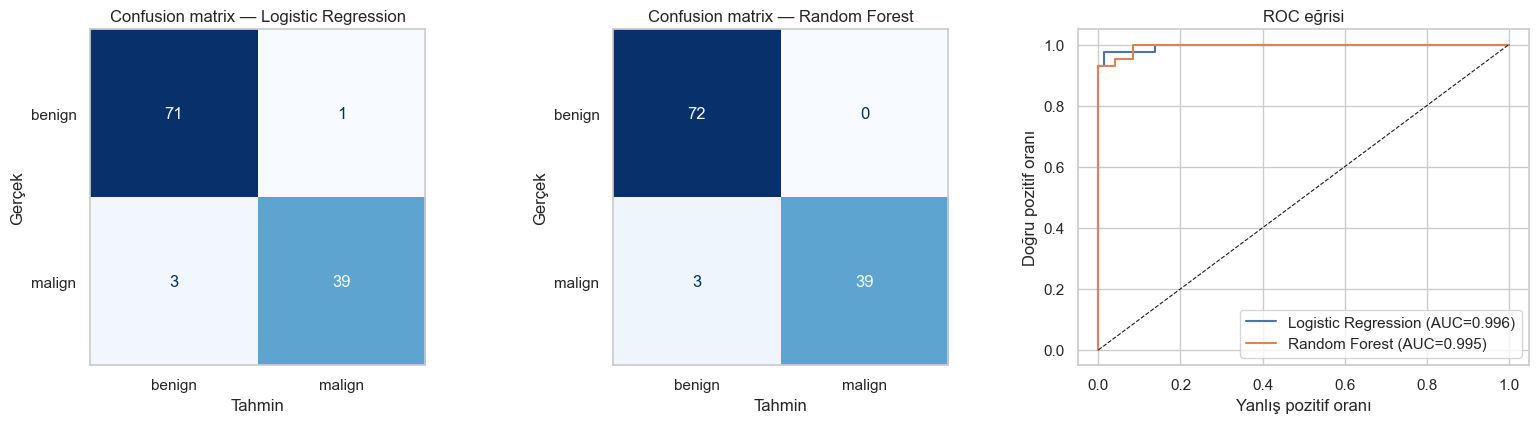

In [5]:
rows, preds, probs = [], {}, {}
for ad, mdl in [("Logistic Regression", lr), ("Random Forest", rf)]:
    p = mdl.predict(X_test); preds[ad] = p; probs[ad] = mdl.predict_proba(X_test)[:, 1]
    rows.append(dict(Model=ad, Accuracy=accuracy_score(y_test, p), Precision=precision_score(y_test, p), Recall=recall_score(y_test, p), F1=f1_score(y_test, p), AUC=roc_auc_score(y_test, probs[ad])))
res = pd.DataFrame(rows).set_index("Model").round(3); display(res)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
for a, (ad, p) in zip(ax[:2], preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=["benign", "malign"]).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(f"Confusion matrix — {ad}"); a.set_xlabel("Tahmin"); a.set_ylabel("Gerçek"); a.grid(False)
for ad in probs:
    fpr, tpr, _ = roc_curve(y_test, probs[ad]); ax[2].plot(fpr, tpr, label=f"{ad} (AUC={roc_auc_score(y_test, probs[ad]):.3f})")
ax[2].plot([0, 1], [0, 1], "k--", lw=.8); ax[2].set_title("ROC eğrisi"); ax[2].set_xlabel("Yanlış pozitif oranı"); ax[2].set_ylabel("Doğru pozitif oranı"); ax[2].legend(loc="lower right")
plt.tight_layout(); plt.savefig("fig_degerlendirme.png", dpi=150); plt.show()

## 8. Hata Analizi

,Model,Gercek,Tahmin,malign_olasiligi,worst_perimeter,mean_texture
0,Logistic Regression,benign,malign,0.509,96.7,30.7
1,Logistic Regression,malign,benign,0.061,110.3,15.8
2,Logistic Regression,malign,benign,0.315,106.4,23.1
3,Logistic Regression,malign,benign,0.492,117.7,16.7
4,Random Forest,malign,benign,0.150,110.3,15.8
5,Random Forest,malign,benign,0.263,108.4,21.5
6,Random Forest,malign,benign,0.161,102.2,23.3


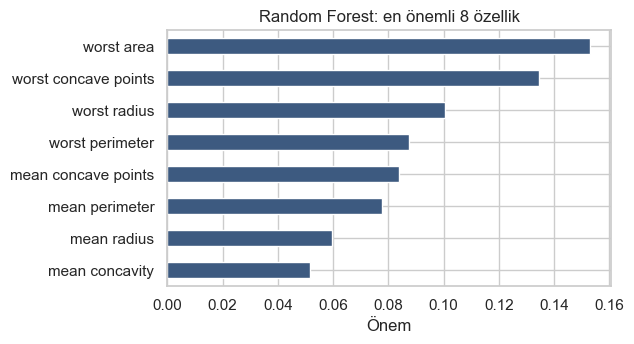

Malign ortalaması worst perimeter: 141.4 | benign: 87.0


In [6]:
err = []
for ad, p in preds.items():
    for i in np.where(p != y_test.values)[0]:
        err.append(dict(Model=ad, Gercek="malign" if y_test.values[i] else "benign", Tahmin="malign" if p[i] else "benign", malign_olasiligi=round(probs[ad][i], 3), worst_perimeter=round(X_test.iloc[i]["worst perimeter"], 1), mean_texture=round(X_test.iloc[i]["mean texture"], 1)))
err = pd.DataFrame(err); display(err)
imp = pd.Series(rf.named_steps["randomforestclassifier"].feature_importances_, index=X.columns).sort_values(ascending=False).head(8)
plt.figure(figsize=(6.5, 3.6)); imp[::-1].plot.barh(color="#3d5a80"); plt.title("Random Forest: en önemli 8 özellik"); plt.xlabel("Önem"); plt.tight_layout(); plt.savefig("fig_onem.png", dpi=150); plt.show()
print("Malign ortalaması worst perimeter:", round(X[y == 1]["worst perimeter"].mean(), 1), "| benign:", round(X[y == 0]["worst perimeter"].mean(), 1))
out = dict(res=res.reset_index().to_dict("records"), cv_lr=[float(cv_lr.mean()), float(cv_lr.std())], cv_rf=[float(cv_rf.mean()), float(cv_rf.std())], best=str(rf_grid.best_params_),
           cm={ad: confusion_matrix(y_test, p).tolist() for ad, p in preds.items()}, err=err.to_dict("records"), imp=imp.round(3).to_dict(), n=len(df), n_mal=int(y.sum()), n_test=len(y_test))
json.dump(out, open("metrics.json", "w"), ensure_ascii=False, indent=1)

## 9. Sonuç
Sonuçlar ve yorumlar rapor dosyasında (`Rapor.docx`) yer almaktadır.